# Real Djinni experience classification
Actual job postings from the published Djinni corpus (UNLP 2024); source revision b56a6054c10f1266a141e37c8df66c79ff2863af.

Target: employer-declared requirements grouped into 0–1, 2–3, and 5+ years. These are not independently verified Junior/Middle/Senior classes.

Protocol: uniform 12,000-row sample after exact deduplication; employer-grouped held-out split; 5 employer-grouped training CV folds; preprocessing fitted within folds. Primary metric: macro F1.

Source and notices: ../data/real/SOURCE_CARD.md and LICENSE. Dataset card declares MIT; upstream repository notice is Apache-2.0. The discrepancy is disclosed.

Run the cells to inspect saved results and verify them. Set REBUILD=True in the optional experiment cell to repeat training.

In [3]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from src.real_experiments import OUT, LABELS, run
from src.verify_real_artifacts import verify
from threadpoolctl import threadpool_limits
%matplotlib inline
print('Project:', ROOT)

Project: /Users/diyarzhvachkin/PycharmProjects/MLEndterm


In [4]:
audit = json.loads((OUT / 'data_audit.json').read_text())
print({k: audit[k] for k in ['raw_rows','after_exact_dedup','sample_rows','train_rows','test_rows','train_companies','test_companies','company_overlap']})
print('Target mapping:', audit['mapping'])
benchmark = pd.read_csv(ROOT / 'data/real/benchmark.csv')
display(benchmark[['Position','Exp Years','target','Primary Keyword','English Level']].head())
display(benchmark.target.value_counts().to_frame('rows'))
print('Numeric aggregates and technology flags + category/English inputs only; salary is absent.')

{'raw_rows': 141897, 'after_exact_dedup': 141897, 'sample_rows': 12000, 'train_rows': 9906, 'test_rows': 2094, 'train_companies': 2811, 'test_companies': 703, 'company_overlap': 0}
Target mapping: {'no_exp': '0–1 years', '1y': '0–1 years', '2y': '2–3 years', '3y': '2–3 years', '5y': '5+ years'}


,Position,Exp Years,target,Primary Keyword,English Level
0,Middle Python Developer,3y,2–3 years,Python,upper
1,Facebook Comment Specialist,no_exp,0–1 years,Marketing,upper
2,Python Developer (Django),1y,0–1 years,Python,intermediate
3,Affiliate Lead,3y,2–3 years,Marketing,upper
4,Senior Node.js Developer (Product. Startup. Eq...,3y,2–3 years,Node.js,upper


,rows
target,
2–3 years,7309
0–1 years,2364
5+ years,2327


Numeric aggregates and technology flags + category/English inputs only; salary is absent.


In [5]:
# Optional full recomputation, using exactly the same source, seed, groups and grids.
REBUILD = False
if REBUILD:
    with threadpool_limits(limits=1):
        run()
else:
    print('Using saved real-data results. Set REBUILD=True to repeat grouped training.')

Using saved real-data results. Set REBUILD=True to repeat grouped training.


,model,cv_mean,cv_std,test_macro_f1,test_accuracy,errors
0,MLP,0.463190,0.015194,0.477597,0.620821,794
1,Boosting,0.459425,0.005754,0.457269,0.629417,776
2,Logistic Regression,0.441848,0.010618,0.457835,0.643266,747
3,Random Forest,0.411309,0.016655,0.437298,0.631805,771
4,KNN,0.401791,0.009828,0.427782,0.602197,833
5,Dummy,0.252727,0.000076,0.250571,0.602197,833


Preferred by grouped training CV: MLP


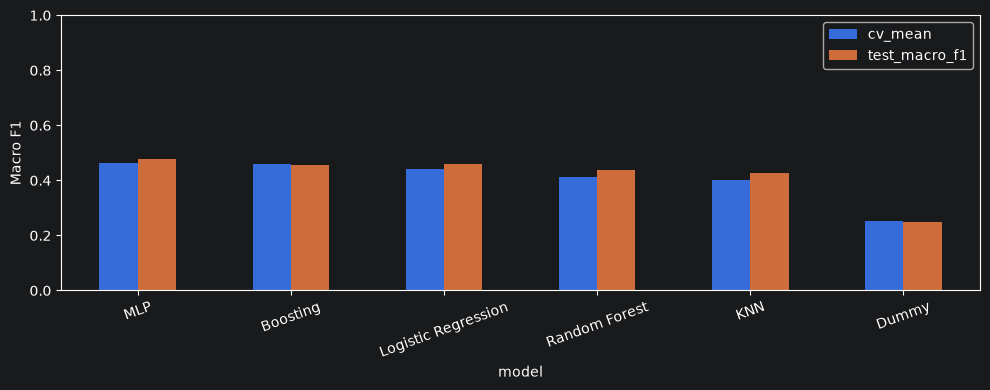

In [6]:
comparison = pd.read_csv(OUT / 'tables/model_comparison.csv')
selection = json.loads((OUT / 'selection.json').read_text())
display(comparison)
print('Preferred by grouped training CV:', selection['preferred_model'])
comparison.set_index('model')[['cv_mean','test_macro_f1']].plot.bar(figsize=(10,4), ylim=(0,1), ylabel='Macro F1', rot=20)
plt.tight_layout()
plt.show()

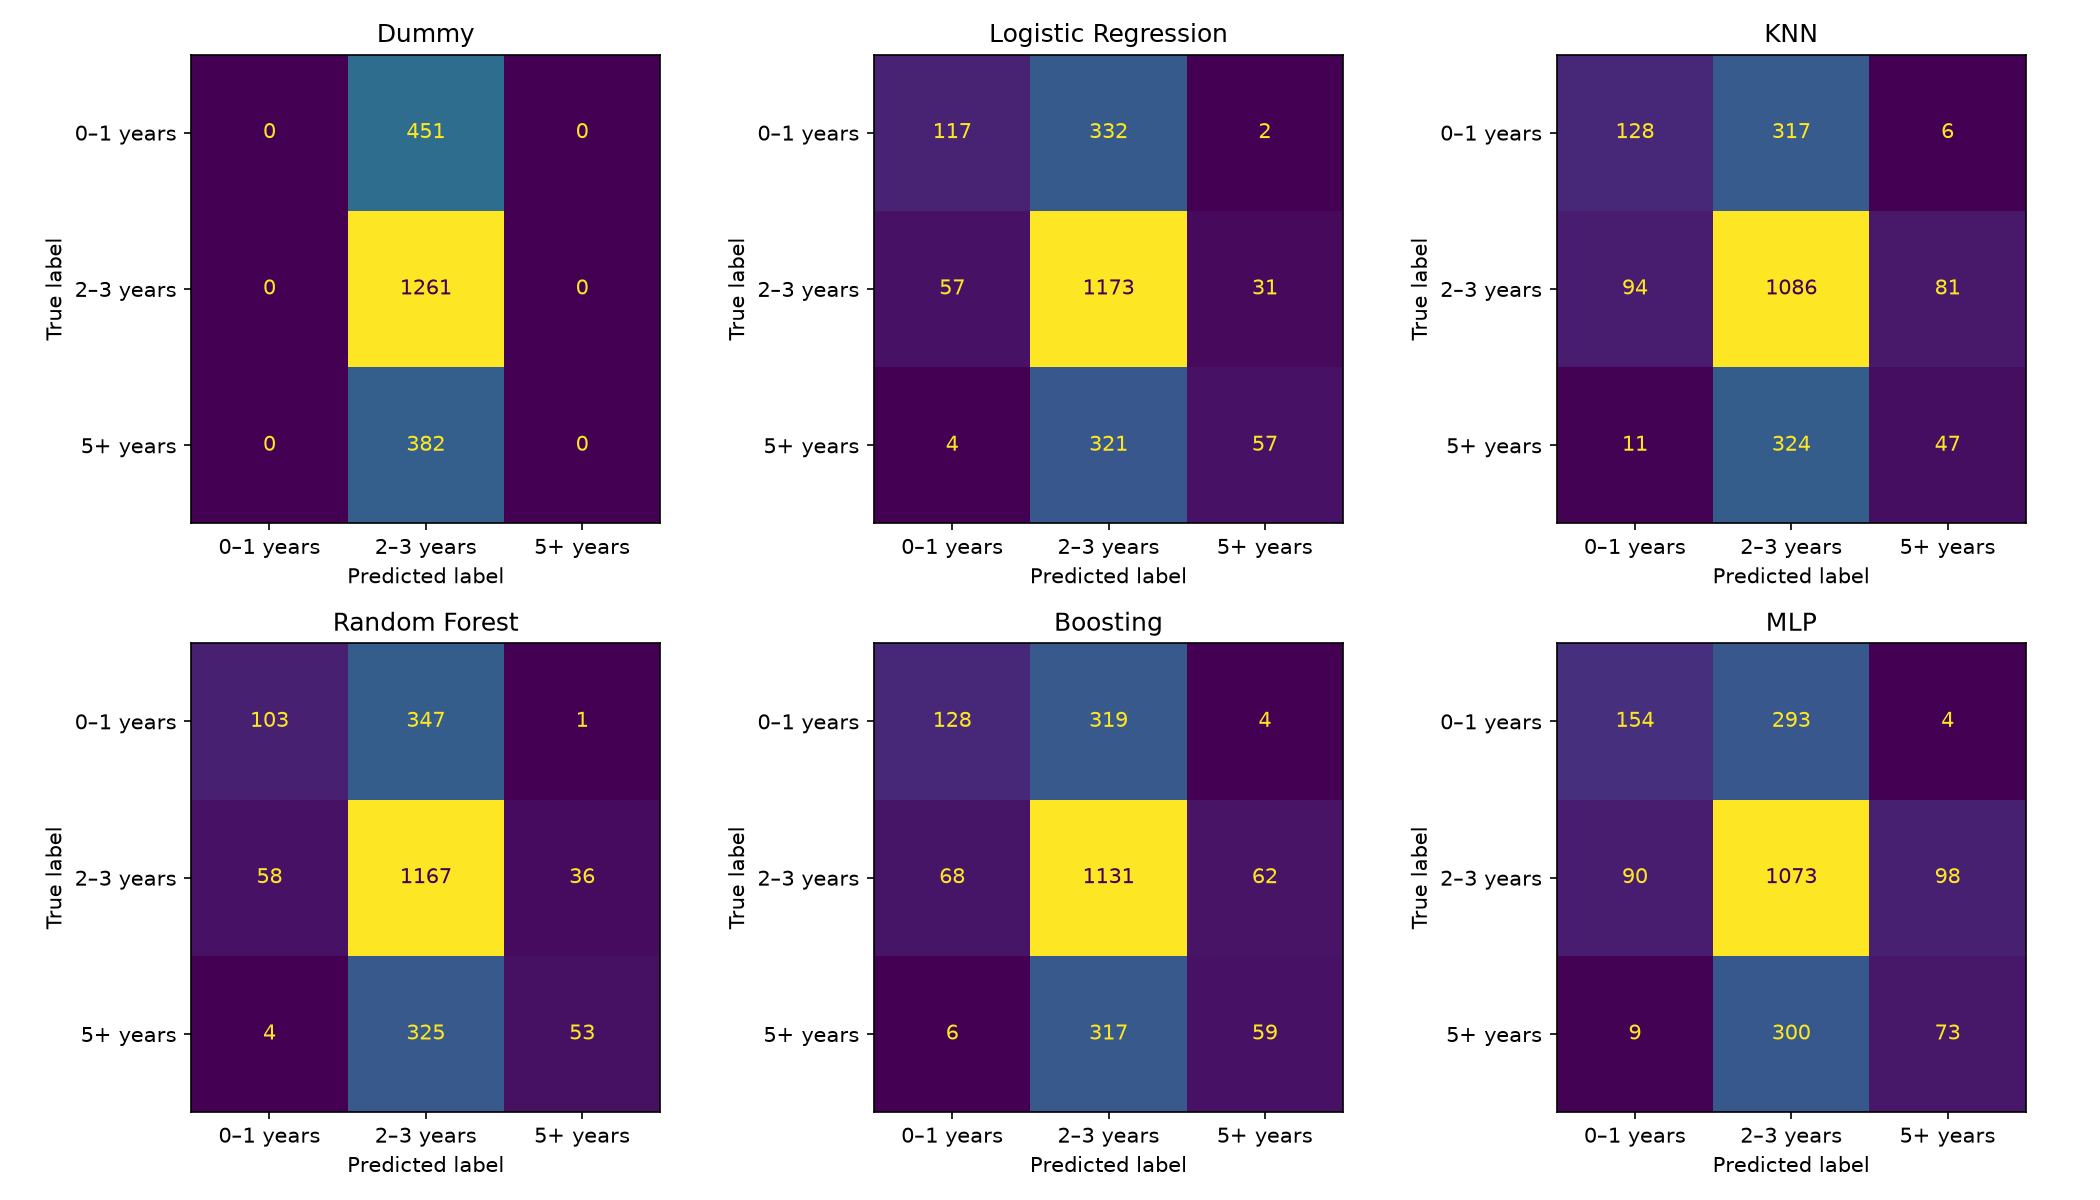

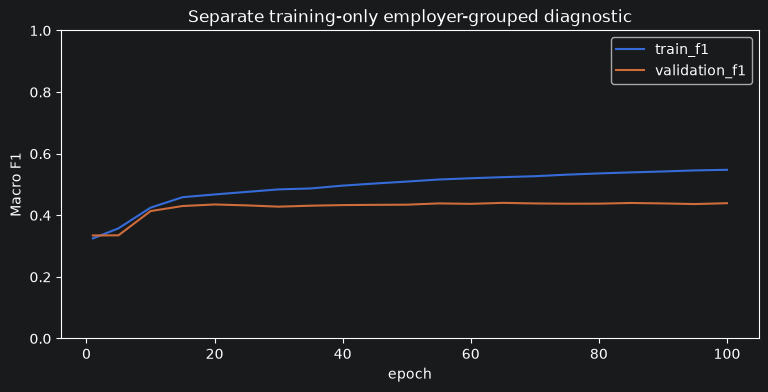

{'input_features': 76, 'hidden': [32], 'output': 3, 'iterations': 180, 'max_iter': 180, 'hit_cap': True, 'alpha': 0.1, 'last_diagnostic': {'epoch': 100, 'loss': 0.7365322276436743, 'train_f1': 0.5476746992164299, 'validation_f1': 0.43928897113636783}, 'diagnostic_fit_rows': 7752, 'diagnostic_validation_rows': 2154}


In [7]:
from IPython.display import Image, display
display(Image(filename=str(OUT / 'figures/confusion_matrices.png')))
learning = pd.read_csv(OUT / 'tables/mlp_learning.csv')
learning.plot(x='epoch', y=['train_f1','validation_f1'], figsize=(9,4), ylim=(0,1), ylabel='Macro F1')
plt.title('Separate training-only employer-grouped diagnostic')
plt.show()
print(json.loads((OUT / 'mlp.json').read_text()))

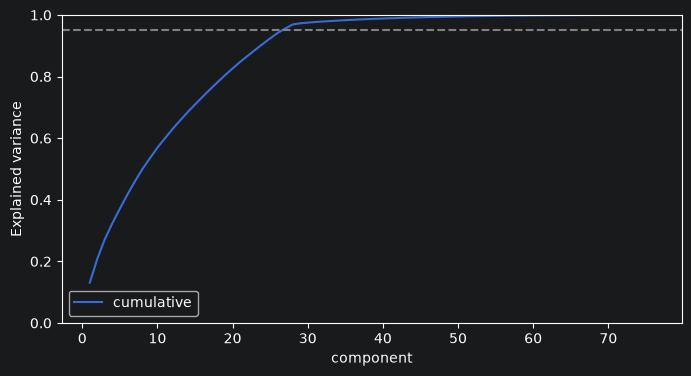

{'features': 76, 'first_two': 0.20831670274160843, 'components95': 27}
PCA is unsupervised and exploratory; not part of the primary model ranking.
{
  "all_six_saved_models_match_predictions": true,
  "metric_recalculation_matches": true,
  "confusion_matrices_match": true,
  "source_hash_matches": true,
  "split_ids_and_order_verified": true,
  "company_overlap": 0,
  "only_approved_inputs_required": true
}


In [8]:
variance = pd.read_csv(OUT / 'tables/pca_variance.csv')
variance.plot(x='component', y='cumulative', figsize=(8,4), ylim=(0,1), ylabel='Explained variance')
plt.axhline(.95, color='gray', linestyle='--')
plt.show()
print(json.loads((OUT / 'pca.json').read_text()))
print('PCA is unsupervised and exploratory; not part of the primary model ranking.')
checks = verify()

## Interpretation and limits
The preferred model is selected by mean grouped training CV macro F1, before held-out prediction. Scores describe the fixed real-data sample, not all job markets. The majority experience band has about 61% of records, so accuracy can conceal weak minority-band recall. Compare every model with Dummy using macro F1 and the confusion matrices.

Employer labels can be noisy; these are declared requirements rather than expert seniority judgments. Company aliases and near-duplicate templates may remain. The sample is English-language and historical. CV spread is not a confidence interval; no nested-CV or significance claim is made.

Full explanation: ../DEFENSE_GUIDE.md. Editable deck: ../presentation/IT_Vacancies.pptx. English script: ../presentation/SCRIPT.md.

Six saved models, their predictions and metrics were verified for consistency.